# 04 · Liquidation math: 5x / 10x / 20x longs through the 10/10 crash

Module **M6: liquidations and cascades** (Phase 0).

**Task.** Implement an approximate liquidation-price function for linear isolated positions,
unit-test it against hand-computed cases, and simulate how many hypothetical 5x/10x/20x longs
opened on Oct 9, 2025 would have been liquidated using real 1-minute candles.

**Market.** Binance USDⓈ-M perpetual **BTCUSDT** (ccxt: exchange `binanceusdm`, symbol
`BTC/USDT:USDT`). For comparison only: Binance **spot** BTC/USDT (exchange `binance`).

**Hypothesis (lab rule 1).** *I believe most 10x and 20x longs opened on Oct 9 were liquidated on
Oct 10, because with leverage L a drop of roughly 1/L (10% and 5%) wipes out the margin, and the
crash of Oct 10 was larger than that. I believe 5x longs mostly survived, because they need a drop
of about 20%. I believe liquidations measured with the mark price are fewer than with the last
price, because the mark price is built to ignore short wicks on one exchange.*
Honesty note: this hypothesis was written **after** Step 0 had shown the minimum price of the
window, so it is not blind.

**Glossary (new terms).**

- **Perpetual (perp)**: a futures contract with no expiry date. Its price is kept close to spot
  by **funding** payments between longs and shorts (module M7).
- **Linear contract**: quoted and settled in USDT. PnL = `qty × (price − entry)` USDT for a long.
- **Leverage (L)**: notional ÷ margin. 1,000 USDT of margin at 10x controls 10,000 USDT of BTC.
- **Isolated margin**: only the margin posted for this position can be lost.
- **Notional**: `qty × price`, the USDT value of the position.
- **Maintenance margin rate (MMR)**: the fraction of the notional the position must keep as
  equity. Below it, the exchange closes the position: **liquidation**.
- **Liquidation price (LP)**: the price where equity = maintenance margin.
- **Last price**: the price of the latest trade on this exchange (normal candles).
- **Mark price**: a price the exchange **computes** (from an index of spot prices on several
  exchanges, plus a funding-based term) and uses to decide liquidations, so that one wild trade
  on its own book does not liquidate everyone.
- **Wick**: the part of a candle between its low (or high) and its body; a short spike.
- **Cascade**: liquidations sell into the market, pushing the price down, which triggers more
  liquidations.

## 1. Setup and parameters

**Parameters fixed before looking at the data** (lab rule 4). Changes after inspection are
labeled as such.

- Window (UTC, start included, end excluded): **2025-10-09 00:00 → 2025-10-11 00:00**, 2 days =
  2,880 one-minute candles per series.
- Three series, all 1-minute: **perp last** (`fetch_ohlcv`, `GET /fapi/v1/klines`), **perp mark**
  (`fetch_ohlcv` with `params={"price": "mark"}`, `GET /fapi/v1/markPriceKlines`) and **spot last**
  (Binance spot, `GET /api/v3/klines`).
- Simulation: one isolated long per minute of 2025-10-09 (00:00–23:59, 1,440 entries) for each
  leverage **5x, 10x, 20x**; margin **1,000 USDT**; entry = **close** of the perp last candle of
  that minute; `qty = margin × L / entry`.
- **MMR = 0.40%, cum = 0** (tier 1 of BTCUSDT, notional 0–300,000 USDT). See the assumption in
  Step 1.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.bitstamp import load_or_fetch_json
from src.data.candles import to_utc, validate_candles
from src.data.ohlcv import (cache_path, fetch_ohlcv_window, fetch_page_with_retry,
                            load_or_fetch_window, make_exchange)
from src.liquidation import (approx_liquidation_price, equity_and_maintenance,
                             liquidation_price_isolated, simulate_isolated_longs)

START, END = to_utc("2025-10-09 00:00"), to_utc("2025-10-11 00:00")
ENTRY_DAY = ("2025-10-09 00:00", "2025-10-09 23:59")
SERIES = {  # name: (ccxt exchange id, symbol, price type)
    "perp last": ("binanceusdm", "BTC/USDT:USDT", None),
    "perp mark": ("binanceusdm", "BTC/USDT:USDT", "mark"),
    "spot last": ("binance", "BTC/USDT", None),
}
LEVERAGES = [5, 10, 20]
MARGIN = 1_000.0       # USDT per position
MMR, CUM = 0.004, 0.0  # tier 1 of BTCUSDT (assumption, see Step 1)
TIER1_MAX_NOTIONAL = 300_000.0
CACHE_DIR = REPO_ROOT / "data" / "raw" / "04_liquidation_math"

pd.set_option("display.width", 120)

## 2. Step 0 · Check the sources before using them

The documentation (read on 2026-11-16) says, for both `GET /fapi/v1/klines` and
`GET /fapi/v1/markPriceKlines`: max `limit` 1500, default 500, `startTime`/`endTime` in ms, oldest
first. Docs:
[Kline](https://developers.binance.com/docs/derivatives/usds-margined-futures/market-data/rest-api/Kline-Candlestick-Data),
[Mark Price Kline](https://developers.binance.com/docs/derivatives/usds-margined-futures/market-data/rest-api/Mark-Price-Kline-Candlestick-Data).

We **measure** instead of trusting them, both on the raw API (ccxt's `fapiPublicGet...` methods,
which send our parameters unchanged) and through ccxt's `fetch_ohlcv`. Results are cached in
`data/`; delete the cache file to measure again.

- `raw API max (asked → got)`: we ask for 1500 and 2000 candles. An error means the API rejects the
  value instead of capping it.
- `ccxt max (asked → got)`: the same through `fetch_ohlcv`, which is what our download uses.
- `field 5 (volume)` and `field 8`: the distinct values in one page of 1,500 raw rows.

In [2]:
RAW_METHOD = {"perp last": "fapiPublicGetKlines", "perp mark": "fapiPublicGetMarkPriceKlines"}


def check_perp_source(name):
    try:
        ex = make_exchange("binanceusdm")
        _, symbol, price = SERIES[name]
        since = int(START.timestamp() * 1000)
        raw = getattr(ex, RAW_METHOD[name])
        raw_caps = {}
        for limit in (None, 1500, 2000):
            params = {"symbol": "BTCUSDT", "interval": "1m", "startTime": since}
            if limit:
                params["limit"] = limit
            try:
                raw_caps[limit] = len(raw(params))
            except Exception as error:
                raw_caps[limit] = f"error: {str(error)[-60:]}"
        page = raw({"symbol": "BTCUSDT", "interval": "1m", "startTime": since, "limit": 1500})
        ccxt_caps = {limit: len(fetch_page_with_retry(ex, symbol, "1m", since, limit, price=price))
                     for limit in (None, 1000, 1500, 2000)}
        stamps = [row[0] for row in page]
        first = fetch_page_with_retry(ex, symbol, "1m", int(to_utc("2017-01-01").timestamp() * 1000),
                                      1, price=price)[0][0]
        now_ms = ex.milliseconds()
        newest = fetch_page_with_retry(ex, symbol, "1m", None, 3, price=price)[-1][0]
        return {
            "default page (raw)": raw_caps[None],
            "raw API max (asked → got)": f"1500→{raw_caps[1500]}, 2000→{raw_caps[2000]}",
            "ccxt max (asked → got)": ", ".join(f"{k}→{v}" for k, v in ccxt_caps.items() if k),
            "raw first timestamp": stamps[0],
            "parsed (ms, UTC)": str(pd.to_datetime(stamps[0], unit="ms", utc=True)),
            "oldest first": stamps == sorted(stamps),
            "field 5 (volume) values": sorted({row[5] for row in page})[:3] if name == "perp mark"
                                       else f"{len({row[5] for row in page})} distinct, min {min(float(r[5]) for r in page)}",
            "field 8 values (count)": ", ".join(
                f"{k}: {n} rows" for k, n in pd.Series([row[8] for row in page]).value_counts().head(3).items())
                if name == "perp mark" else "number of trades",
            "first 1m candle (UTC)": str(pd.to_datetime(first, unit="ms", utc=True)),
            "last candle still forming": newest + 60_000 > now_ms,
            "checked at (UTC)": str(pd.to_datetime(now_ms, unit="ms", utc=True).floor("s")),
        }
    except Exception as error:  # report, do not hide
        return {"access": f"{type(error).__name__}: {str(error)[:120]}"}


source_checks = load_or_fetch_json(CACHE_DIR / "source_checks.json",
                                   lambda: {n: check_perp_source(n) for n in RAW_METHOD})
pd.DataFrame(source_checks)

,perp last,perp mark
default page (raw),500,500
raw API max (asked → got),"1500→1500, 2000→error: -1130,""msg"":""Data sent ...","1500→1500, 2000→error: -1130,""msg"":""Data sent ..."
ccxt max (asked → got),"1000→1000, 1500→1000, 2000→1000","1000→1000, 1500→1000, 2000→1000"
raw first timestamp,1759968000000,1759968000000
"parsed (ms, UTC)",2025-10-09 00:00:00+00:00,2025-10-09 00:00:00+00:00
oldest first,True,True
field 5 (volume) values,"1488 distinct, min 3.143",[0]
field 8 values (count),number of trades,"60: 1498 rows, 59: 2 rows"
first 1m candle (UTC),2019-09-08 17:57:00+00:00,2019-12-23 11:58:00+00:00
last candle still forming,True,True


**Technical sheet (same format as notebook 03).**

| | Binance spot (notebook 03) | Binance USDⓈ-M perp, last | Binance USDⓈ-M perp, mark |
|---|---|---|---|
| Max per request | 1000 | **API accepts 1500; ccxt caps at 1000** (2000 → error −1130) | **API accepts 1500; ccxt caps at 1000** |
| Default | 500 | 500 | 500 |
| Timestamp | ms, open time, UTC | ms, open time, UTC | ms, open time, UTC |
| Order | oldest first | oldest first | oldest first |
| First 1m candle | 2017-08-17 04:00 UTC | 2019-09-08 17:57 UTC | 2019-12-23 11:58 UTC |
| Last candle | still forming → dropped | still forming → dropped | still forming → dropped |
| Volume | traded BTC | traded BTC | **always 0**: the mark is a computed price, nothing trades at it |
| Field 8 | number of trades | number of trades | **Ignore according to the docs** (it is 60 almost always); not used |

We download with ccxt, 1000 candles per request (`EXCHANGE_MAX_LIMIT["binanceusdm"]` in
`src/data/ohlcv.py`). Last and mark are cached in **separate files** whose name ends in the price
type (`..._last.parquet`, `..._mark.parquet`), so one series can never be read as the other.

### 2.1 Download, coverage and quality

`fetch_ohlcv_window` downloads candles with open time in `[start, end)`, removes duplicates and the
candle still forming, and never fills a gap. The checks below stop the notebook if anything is off.

In [3]:
frames, infos = {}, {}
for name, (ex_id, symbol, price) in SERIES.items():
    path = cache_path(CACHE_DIR, ex_id, symbol, "1m", "oct9-10", price=price)
    frames[name], infos[name] = load_or_fetch_window(
        path, lambda: fetch_ohlcv_window(ex_id, symbol, START, END, price=price))

for name, df in frames.items():
    assert str(df.index.tz) == "UTC", name
    assert df.index.is_unique and df.index.is_monotonic_increasing, name
    assert df.index.min() >= START and df.index.max() < END, name
    assert (df[["open", "high", "low", "close"]] > 0).all().all(), name
    assert (df["high"] >= df[["open", "close", "low"]].max(axis=1)).all(), name
    assert (df["low"] <= df[["open", "close", "high"]].min(axis=1)).all(), name

last, mark, spot = frames["perp last"], frames["perp mark"], frames["spot last"]


def coverage_row(name, df):
    report = validate_candles(df, START, END - pd.Timedelta(minutes=1))
    i_low = df["low"].idxmin()
    return {"candles": report["candles"], "expected": report["expected"],
            "missing": report["missing"], "duplicates dropped": infos[name]["duplicates_dropped"],
            "volume == 0": int((df["volume"] == 0).sum()),
            "O=H=L=C": int(((df["open"] == df["high"]) & (df["high"] == df["low"])
                            & (df["low"] == df["close"])).sum()),
            "min low": round(df["low"].min(), 2), "min low at (UTC)": f"{i_low:%m-%d %H:%M}"}


coverage = pd.DataFrame({name: coverage_row(name, df) for name, df in frames.items()}).T
coverage

,candles,expected,missing,duplicates dropped,volume == 0,O=H=L=C,min low,min low at (UTC)
perp last,2880,2880,0,0,0,0,101516.5,10-10 21:20
perp mark,2880,2880,0,0,2880,0,101877.69,10-10 21:20
spot last,2880,2880,0,0,0,0,102000.0,10-10 21:20


How to read it: one row per series. `volume == 0` is a filled candle for a traded series; for the
**mark** it is every candle, because the mark has no volume (not a quality problem). `O=H=L=C`
counts candles that are flat (a typical filled candle). `min low` is the lowest price of the
2 days.

### 2.2 Quick comparison: perp vs spot, last vs mark, calm day vs crash day

Differences in bps, `(a / b − 1) × 10,000`, minute by minute, using the `close` or the `low` of the
same minute. Oct 9 is the calm day; Oct 10 contains the crash.

In [4]:
COMPARISONS = {  # label: (series a, series b, column)
    "close perp − spot": ("perp last", "spot last", "close"),
    "low perp − spot": ("perp last", "spot last", "low"),
    "close last − mark": ("perp last", "perp mark", "close"),
    "low last − mark": ("perp last", "perp mark", "low"),
}
# Added after inspecting this table (see the note below it).
NOTES = {("2025-10-10", "low perp − spot"):
         "max: one single minute, caused by the spot wick; it does not mean the perp was ~5% more expensive"}

rows = {}
for day in ["2025-10-09", "2025-10-10"]:
    for label, (a, b, col) in COMPARISONS.items():
        d = (10_000 * (frames[a][col] / frames[b][col] - 1)).loc[day]
        rows[day, label] = {"minutes": len(d), "median (bps)": round(d.median(), 1),
                            "p95 |diff| (bps)": round(d.abs().quantile(0.95), 1),
                            "min (bps)": round(d.min(), 1), "min at": f"{d.idxmin():%H:%M}",
                            "max (bps)": round(d.max(), 1), "max at": f"{d.idxmax():%H:%M}",
                            "note": NOTES.get((day, label), "")}
comparison = pd.DataFrame(rows).T
comparison.index.names = ["day (UTC)", "difference"]
comparison

minutes median (bps) p95 |diff| (bps) min (bps) min at max (bps) max at  \
day (UTC)  difference                                                                                  
2025-10-09 close perp − spot    1440         -4.6              5.7      -6.8  23:59      -2.6  13:22   
           low perp − spot      1440         -4.8              6.1     -10.7  14:46      -1.0  13:30   
           close last − mark    1440         -0.0              1.9      -7.5  13:51       4.5  14:46   
           low last − mark      1440         -0.2              1.9      -6.6  14:46       2.4  03:28   
2025-10-10 close perp − spot    1440         -4.6              6.4     -51.4  21:19      77.1  21:27   
           low perp − spot      1440         -4.9              7.5    -154.8  21:19     527.1  21:24   
           close last − mark    1440         -0.0              4.1     -91.2  21:19      50.2  21:27   
           low last − mark      1440         -0.3              5.3    -132.8  21:19      27.4  21:32   

                                                                           note  
day (UTC)  difference                                                            
2025-10-09 close perp − spot                                                     
           low perp − spot                                                       
           close last − mark                                                     
           low last − mark                                                       
2025-10-10 close perp − spot                                                     
           low perp − spot    max: one single minute, caused by the spot wic...  
           close last − mark                                                     
           low last − mark

**A real wick on a thin book (spot, 2025-10-10 21:24 UTC).** The spot candle of 21:24 opened at
107,571 and closed at 108,219, but its low was **102,000.0**, exactly the same round number as the
spot minimum of 21:20. Neither the perp last nor the mark went near it. The same candle is in
notebook 03's cache, so it is Binance's data, not a download error. A likely reading: one sell
order swept a thin book down to a large buy order resting at 102,000. We keep it as it is; it does
not enter the simulation, which uses only the perp.

**Observation, not explained here.** The perp traded about **4.6 bps below spot** (median) on both
days, calm or not. This is revisited in **M7 (funding)**.

In [5]:
wick = pd.concat({"spot": spot[["open", "low", "close"]], "perp last": last[["low", "close"]],
                  "perp mark": mark[["low", "close"]]}, axis=1)
wick.loc["2025-10-10 21:19":"2025-10-10 21:25"].round(1)

spot                     perp last           perp mark          
                               open       low     close       low     close       low     close
open_time_utc                                                                                  
2025-10-10 21:19:00+00:00  108822.0  103800.0  103975.3  102193.6  103441.3  103568.5  104393.2
2025-10-10 21:20:00+00:00  104113.8  102000.0  104384.6  101516.5  104311.2  101877.7  104386.2
2025-10-10 21:21:00+00:00  104411.8  103255.1  106766.1  104212.8  106416.5  104267.8  107006.9
2025-10-10 21:22:00+00:00  106767.7  106252.9  107196.0  106375.4  107274.1  106750.2  107213.2
2025-10-10 21:23:00+00:00  107193.0  106461.5  107478.8  107202.5  107747.3  107292.5  107676.4
2025-10-10 21:24:00+00:00  107571.2  102000.0  108219.1  107376.9  108473.0  107266.9  108677.9
2025-10-10 21:25:00+00:00  108219.1  106388.6  106891.5  106982.9  107111.6  107131.8  107131.8

## 3. Step 1 · The liquidation price

Code in `src/liquidation.py`, tests in `tests/test_liquidation.py`.

The exchange liquidates an isolated position when its **equity** (margin + unrealized PnL) falls
to its **maintenance margin** (`notional × MMR − cum`, with notional at the current price).
Solving that equality for the price gives Binance's formula for isolated, one-way mode (wallet
balance = isolated margin, other positions = 0):

$$\text{long: } LP = \frac{\text{margin} + \text{cum} - \text{qty}\cdot\text{entry}}{\text{qty}\cdot\text{MMR} - \text{qty}}
\qquad
\text{short: } LP = \frac{\text{margin} + \text{cum} + \text{qty}\cdot\text{entry}}{\text{qty}\cdot\text{MMR} + \text{qty}}$$

Sources: [liquidation price](https://www.binance.com/en/support/faq/b3c689c1f50a44cabb3a84e663b81d93),
[maintenance margin = notional × MMR − cum](https://www.binance.com/en/support/faq/360033162192).

**The shortcut.** With leverage L, the margin is 1/L of the notional, so a drop of about 1/L wipes
it out; the exchange steps in a little earlier, when only MMR is left:
`LP ≈ entry × (1 − 1/L + MMR)` for a long, `entry × (1 + 1/L − MMR)` for a short.

**ASSUMPTION — MMR = 0.40%, cum = 0.** Tier 1 of BTCUSDT (notional 0–300,000 USDT) after Binance's
update of 2025-08-17/18
([announcement](https://www.binance.com/en/support/announcement/detail/8e428625ebeb4cc7ae8678026846095c)).
No change for BTCUSDT between that date and 2025-10-09 was found, but this is **not confirmed**.
All simulated positions must fall in tier 1 (checked below).

The table recomputes the unit-test cases (hand values computed in the chat before coding).
Case 6 checks the identity "equity = maintenance margin at LP", where the PnL is
`qty × (LP − entry)` for a long and `qty × (entry − LP)` for a short.

In [6]:
E, Q = 100_000.0, 0.1
cases = [
    ("1 long, margin 1,000, MMR 0.50%", 90_452.26, liquidation_price_isolated("long", E, Q, 1_000, 0.005)),
    ("2 long, margin 1,000, MMR 0.40%", 90_361.45, liquidation_price_isolated("long", E, Q, 1_000, 0.004)),
    ("3 short, margin 1,000, MMR 0.40%", 109_561.75, liquidation_price_isolated("short", E, Q, 1_000, 0.004)),
    ("4 long 100x, margin 100, MMR 0.40%", 99_397.59, liquidation_price_isolated("long", E, Q, 100, 0.004)),
    ("5 shortcut of case 1 (10x)", 90_500.00, approx_liquidation_price("long", E, 10, 0.005)),
]
tests = pd.DataFrame([{"case": c, "by hand": h, "function": round(f, 4), "diff": round(f - h, 4),
                       "pass (±0.01)": abs(f - h) <= 0.01} for c, h, f in cases]).set_index("case")
gap_pct = 100 * (cases[4][2] - cases[0][2]) / cases[0][2]
for side in ["long", "short"]:
    lp = liquidation_price_isolated(side, E, Q, 1_000, MMR)
    equity, maint = equity_and_maintenance(side, lp, E, Q, 1_000, MMR)
    tests.loc[f"6 identity at LP, {side} (equity vs maintenance)"] = [round(maint, 4), round(equity, 4),
                                                                      round(equity - maint, 6),
                                                                      abs(equity - maint) <= 0.01]
print(f"shortcut vs exact (case 5 vs case 1): {gap_pct:.3f}% above the exact LP")
assert tests["pass (±0.01)"].all() and gap_pct < 0.1
tests

shortcut vs exact (case 5 vs case 1): 0.053% above the exact LP


,by hand,function,diff,pass (±0.01)
case,,,,
"1 long, margin 1,000, MMR 0.50%",90452.2600,90452.2613,0.0013,True
"2 long, margin 1,000, MMR 0.40%",90361.4500,90361.4458,-0.0042,True
"3 short, margin 1,000, MMR 0.40%",109561.7500,109561.7530,0.0030,True
"4 long 100x, margin 100, MMR 0.40%",99397.5900,99397.5904,0.0004,True
5 shortcut of case 1 (10x),90500.0000,90500.0000,0.0000,True
"6 identity at LP, long (equity vs maintenance)",36.1446,36.1446,-0.0000,True
"6 identity at LP, short (equity vs maintenance)",43.8247,43.8247,-0.0000,True


## 4. Step 2 · Simulation: longs opened on Oct 9

For every minute `t` of 2025-10-09 and every leverage L:

1. **Entry** = close of the perp last candle of minute `t`; `qty = 1,000 × L / entry`.
2. **LP** = exact isolated formula with MMR 0.40%, cum 0.
3. **No look-ahead:** liquidation is checked from the minute **after** `t` up to the last minute
   before 2025-10-11 00:00. The low of minute `t` itself happened before the close we enter at.
4. **Liquidated (main)** = first minute whose **mark** low is ≤ LP. **Comparison** = the same with
   the **last** low.

Approximations, stated up front:

- The **low of a 1-minute mark candle** stands in for the real mark price, which Binance updates
  more often than once a minute. A touch inside the minute is caught; the exact second is not.
- **Fees and funding are ignored.** The opening fee would reduce the margin and move LP **closer**
  to the entry, so the real liquidation counts can only be equal or higher. Funding over the
  ~1–2 days held could go either way.
- No liquidation fee, no partial liquidation, no slippage when the position is closed: we only
  ask **whether** the LP was reached, not what the trader got back (with isolated margin it is at
  most the 1,000 USDT lost).

In [7]:
entry_close = last.loc[ENTRY_DAY[0]:ENTRY_DAY[1], "close"]
assert len(entry_close) == 1_440, len(entry_close)
for name in ["perp last", "perp mark"]:  # the checks need every minute after each entry
    assert validate_candles(frames[name], START, END - pd.Timedelta(minutes=1))["missing"] == 0, name

sim = simulate_isolated_longs(entry_close, {"mark": mark["low"], "last": last["low"]},
                              LEVERAGES, MARGIN, MMR, CUM)
assert (sim["notional"] <= TIER1_MAX_NOTIONAL).all()   # every position is in tier 1
entry_times = sim.index.get_level_values("entry_time")
for price in ["mark", "last"]:  # a liquidation can never be at or before its own entry minute
    assert (entry_times.to_numpy() < sim[f"liquidated_{price}"].fillna(END).to_numpy()).all()
print(f"{len(sim):,} positions; notional per leverage (USDT):",
      sim.groupby(level="leverage")["notional"].max().round(2).to_dict())
sim.head()

4,320 positions; notional per leverage (USDT): {5: 5000.0, 10: 10000.0, 20: 20000.0}


entry       qty  notional  opening_fee            lp  drop_to_lp_pct  \
leverage entry_time                                                                                           
5        2025-10-09 00:00:00+00:00  123272.9  0.040560    5000.0          0.0  99014.377510       19.678715   
         2025-10-09 00:01:00+00:00  123242.8  0.040570    5000.0          0.0  98990.200803       19.678715   
         2025-10-09 00:02:00+00:00  123214.0  0.040580    5000.0          0.0  98967.068273       19.678715   
         2025-10-09 00:03:00+00:00  123208.0  0.040582    5000.0          0.0  98962.248996       19.678715   
         2025-10-09 00:04:00+00:00  123156.6  0.040599    5000.0          0.0  98920.963855       19.678715   

                                   liquidated_mark liquidated_last  
leverage entry_time                                                 
5        2025-10-09 00:00:00+00:00             NaT             NaT  
         2025-10-09 00:01:00+00:00             NaT             NaT  
         2025-10-09 00:02:00+00:00             NaT             NaT  
         2025-10-09 00:03:00+00:00             NaT             NaT  
         2025-10-09 00:04:00+00:00             NaT             NaT

### T1 · How many were liquidated?

Per leverage: share of the 1,440 positions liquidated by the mark (main) and by the last
(comparison), the median drop from entry to LP, and the median UTC time of liquidation among the
liquidated ones.

In [8]:
def fmt(ts):
    return f"{ts:%m-%d %H:%M}"


def t1_row(group):
    row = {"positions": len(group),
           "LP drop from entry, median (%)": round(group["drop_to_lp_pct"].median(), 2),
           "shortcut drop 1/L − MMR (%)": round(100 * (1 / group.name - MMR), 2)}
    for price in ["mark", "last"]:
        hit = group[f"liquidated_{price}"].dropna()
        row[f"liquidated, {price} (%)"] = round(100 * len(hit) / len(group), 1)
        row[f"median liq. time, {price} (UTC)"] = fmt(hit.median()) if len(hit) else "—"
    # Added after inspecting the data: the median alone hid how spread out the times were.
    # p10/p90 use interpolation="nearest", so they are real minutes of the sample.
    hit = group["liquidated_mark"].dropna()
    for label, value in [("first", hit.min() if len(hit) else None),
                         ("p10", hit.quantile(0.10, interpolation="nearest") if len(hit) else None),
                         ("p90", hit.quantile(0.90, interpolation="nearest") if len(hit) else None),
                         ("last", hit.max() if len(hit) else None)]:
        row[f"[post-inspection] {label} liq. time, mark (UTC)"] = fmt(value) if value is not None else "—"
    return pd.Series(row)


t1 = sim.groupby(level="leverage").apply(t1_row)
t1.T

leverage,5,10,20
positions,1440,1440,1440
"LP drop from entry, median (%)",19.68,9.64,4.62
shortcut drop 1/L − MMR (%),19.6,9.6,4.6
"liquidated, mark (%)",0.0,100.0,100.0
"median liq. time, mark (UTC)",—,10-10 21:13,10-10 19:21
"liquidated, last (%)",0.0,100.0,100.0
"median liq. time, last (UTC)",—,10-10 21:13,10-10 19:21
"[post-inspection] first liq. time, mark (UTC)",—,10-10 21:13,10-10 17:05
"[post-inspection] p10 liq. time, mark (UTC)",—,10-10 21:13,10-10 18:52
"[post-inspection] p90 liq. time, mark (UTC)",—,10-10 21:17,10-10 20:54


**Added after inspecting the data.** Which exact minutes hold the 10x liquidations, and are they
inside 20:50–21:30 UTC of Oct 10 (the window shaded in G1)? Count of positions per minute, by mark
(main) and by last (comparison).

In [9]:
CRASH_WINDOW = (to_utc("2025-10-10 20:50"), to_utc("2025-10-10 21:30"))  # end included
ten = sim.xs(10, level="leverage")
minutes_10x = pd.DataFrame({price: ten[f"liquidated_{price}"].value_counts()
                            for price in ["mark", "last"]}).fillna(0).astype(int).sort_index()
minutes_10x.index = minutes_10x.index.strftime("%m-%d %H:%M")
minutes_10x.loc["total"] = minutes_10x.sum()
for price in ["mark", "last"]:
    t = ten[f"liquidated_{price}"]
    inside = t.between(*CRASH_WINDOW).sum()
    print(f"10x by {price}: {inside} of {t.notna().sum()} liquidations inside 20:50–21:30 UTC")
minutes_10x

10x by mark: 1440 of 1440 liquidations inside 20:50–21:30 UTC
10x by last: 1440 of 1440 liquidations inside 20:50–21:30 UTC


,mark,last
10-10 21:13,863,1326
10-10 21:16,245,98
10-10 21:17,332,16
total,1440,1440


### G1 · Price path and the typical liquidation prices

Both panels plot the **1-minute low** (the value the simulation compares with LP) of the perp
**last** (blue) and the perp **mark** (orange), in USDT. Horizontal lines: the **median LP** of the
1,440 positions of each leverage (the LPs of one leverage span a band, printed below, because the
entries span 119,752–123,655). Shaded: 20:50–21:30 UTC on Oct 10.
Top: the whole window (Oct 9–10). Bottom: zoom on 20:00–22:00 UTC of Oct 10, same unit, its own
y-scale.

LP per leverage (USDT):
               min    median       max
leverage                              
5          96186.0   97780.0   99321.0
10        108210.0  110003.0  111737.0
20        114221.0  116114.0  117944.0


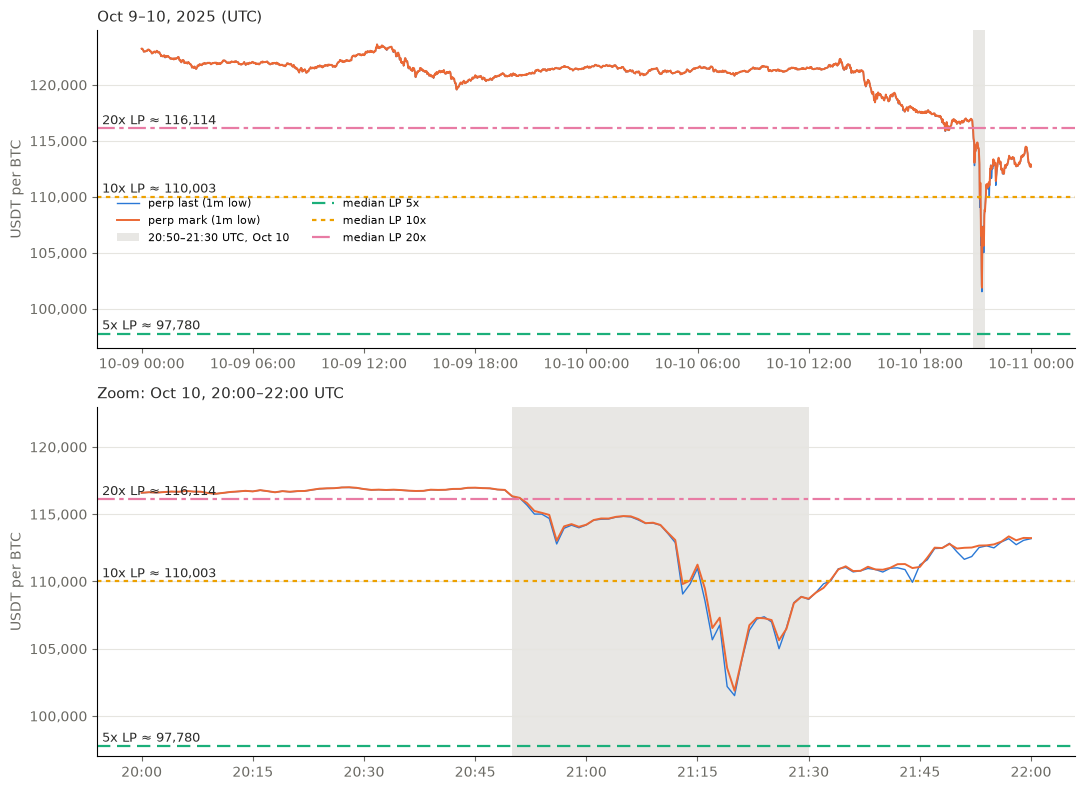

In [10]:
SERIES_COLORS = {"last": "#2a78d6", "mark": "#eb6834"}            # fixed per series
LEV_STYLE = {5: ("#1baf7a", (0, (6, 3))), 10: ("#eda100", (0, (2, 2))),  # fixed per leverage:
             20: ("#e87ba4", (0, (8, 2, 2, 2)))}                         # color + dash pattern
INK, MUTED = "#2b2b2a", "#6b6a64"

lp_band = sim.groupby(level="leverage")["lp"].agg(["min", "median", "max"]).round(0)
print("LP per leverage (USDT):")
print(lp_band.to_string())

zoom = slice("2025-10-10 20:00", "2025-10-10 22:00")
fig, axes = plt.subplots(2, 1, figsize=(11, 8), height_ratios=[1, 1.1])
for ax, window, title in [(axes[0], slice(None), "Oct 9–10, 2025 (UTC)"),
                          (axes[1], zoom, "Zoom: Oct 10, 20:00–22:00 UTC")]:
    for name, df in [("last", last), ("mark", mark)]:
        ax.plot(df.loc[window, "low"], color=SERIES_COLORS[name], lw=1.0 if name == "last" else 1.4,
                label=f"perp {name} (1m low)")
    ax.axvspan(*CRASH_WINDOW, color="#d9d8d2", alpha=0.6, lw=0, label="20:50–21:30 UTC, Oct 10")
    x_label = ax.get_xlim()[0]
    for lev, (color, dash) in LEV_STYLE.items():
        y = lp_band.loc[lev, "median"]
        ax.axhline(y, color=color, ls=dash, lw=1.6, label=f"median LP {lev}x")
        ax.annotate(f"{lev}x LP ≈ {y:,.0f}", xy=(0.005, y), xycoords=("axes fraction", "data"),
                    xytext=(0, 3), textcoords="offset points", fontsize=9, color=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_ylabel("USDT per BTC", color=MUTED)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M", tz="UTC"))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
axes[1].set_ylim(97_000, 123_000)
axes[0].legend(loc="center left", bbox_to_anchor=(0.01, 0.4), fontsize=8, frameon=False, ncol=2)
fig.tight_layout()
plt.show()

### G2 · Cumulative share liquidated over time (mark)

y-axis: % of the 1,440 positions of each leverage already liquidated by the **mark** at each minute
(it can only go up). x-axis: time in UTC. Left: the whole window. Right: zoom on Oct 10,
16:00–22:00, where all the action is. Shaded: 20:50–21:30 UTC on Oct 10.

         1% reached at (UTC) 50% reached at (UTC) 100% reached at (UTC)
leverage                                                               
5                      never                never                 never
10               10-10 21:13          10-10 21:13           10-10 21:17
20               10-10 17:09          10-10 19:21           10-10 20:56


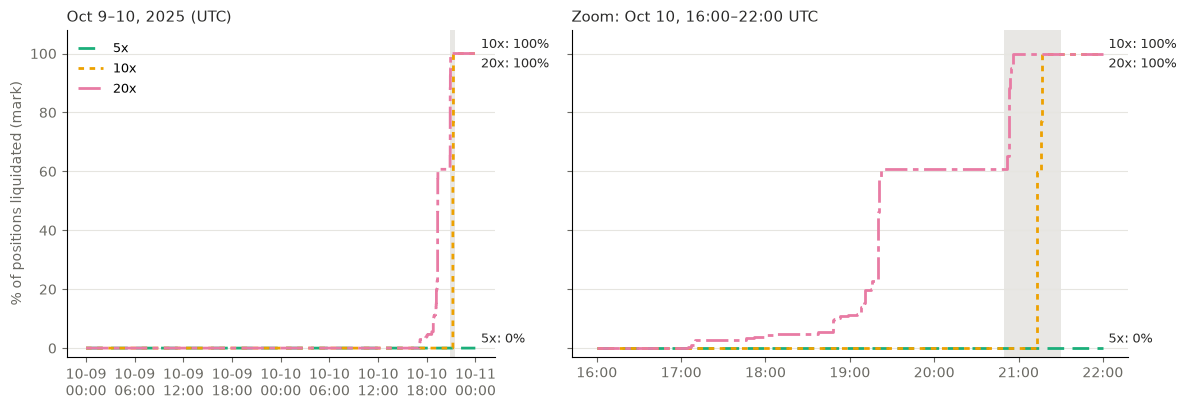

In [11]:
grid = mark.index  # every minute of the window
cumulative = pd.DataFrame({
    lev: 100 * sim.xs(lev, level="leverage")["liquidated_mark"].value_counts()
                  .reindex(grid, fill_value=0).cumsum() / 1_440
    for lev in LEVERAGES})

# When did each leverage reach 50% and 100% liquidated?
milestones = pd.DataFrame({
    lev: {f"{pct}% reached at (UTC)": fmt(cumulative[lev][cumulative[lev] >= pct].index[0])
          if (cumulative[lev] >= pct).any() else "never" for pct in (1, 50, 100)}
    for lev in LEVERAGES}).T
milestones.index.name = "leverage"
print(milestones.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), width_ratios=[1, 1.3], sharey=True)
for ax, window in [(axes[0], slice(None)), (axes[1], slice("2025-10-10 16:00", "2025-10-10 22:00"))]:
    for lev, (color, dash) in LEV_STYLE.items():
        s = cumulative.loc[window, lev]
        ax.plot(s.index, s, color=color, ls=dash, lw=2, drawstyle="steps-post", label=f"{lev}x")
        ax.annotate(f"{lev}x: {s.iloc[-1]:.0f}%", xy=(s.index[-1], s.iloc[-1]), xytext=(4, -10 if lev == 20 else 4),
                    textcoords="offset points", fontsize=9, color=INK)
    ax.axvspan(*CRASH_WINDOW, color="#d9d8d2", alpha=0.6, lw=0)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[0].set_title("Oct 9–10, 2025 (UTC)", loc="left", fontsize=11, color=INK)
axes[1].set_title("Zoom: Oct 10, 16:00–22:00 UTC", loc="left", fontsize=11, color=INK)
axes[0].set_ylabel("% of positions liquidated (mark)", color=MUTED)
axes[0].set_ylim(-3, 108)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M", tz="UTC"))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
axes[0].legend(loc="upper left", fontsize=9, frameon=False)
fig.tight_layout()
plt.show()

### Sensitivity of the timing (added after inspecting the data)

G2 showed that the 20x survivors' highest LP (115,896) was only **2 USDT** below the mark's low of
19:22 (115,898), so the *timing* of 20x liquidations may hinge on small assumptions. Four variants:

- **(a) base**: margin 1,000, MMR 0.40% (the main result above).
- **(b) opening fee out of the margin — pessimistic**: Binance charges fees on the **notional**
  (fee = notional × rate; regular-user taker rate 0.05%,
  [source](https://www.binance.com/en/support/faq/360033544231)), i.e. 2.5 / 5 / 10 USDT for
  5x / 10x / 20x. Here it is taken **out of the isolated margin**, as if the opening fee came from
  it. That Binance deducts it from the isolated margin is **not verified**; this is the
  pessimistic case.
- **(c) MMR 0.50%** instead of 0.40%.
- **(d)** (b) and (c) together.

Columns: % liquidated by the mark; first, p10, median, p90 and last liquidation time (UTC);
mean LP shift vs (a) in USDT (positive = LP moved **up**, closer to the entry); and two counts
of positions: liquidated **by 19:30 UTC** on Oct 10 (before the 20x plateau seen in G2) and
liquidated **inside 20:50–21:30 UTC**.

In [12]:
TAKER_FEE = 0.0005
PLATEAU_START = to_utc("2025-10-10 19:30")
VARIANTS = {"(a) base": dict(mmr=MMR, opening_fee_rate=0.0),
            "(b) fee out of margin": dict(mmr=MMR, opening_fee_rate=TAKER_FEE),
            "(c) MMR 0.50%": dict(mmr=0.005, opening_fee_rate=0.0),
            "(d) fee + MMR 0.50%": dict(mmr=0.005, opening_fee_rate=TAKER_FEE)}
runs = {name: simulate_isolated_longs(entry_close, {"mark": mark["low"]}, LEVERAGES, MARGIN,
                                      cum=CUM, **kw) for name, kw in VARIANTS.items()}
print("opening fee per position (USDT):",
      runs["(b) fee out of margin"].groupby(level="leverage")["opening_fee"].mean().round(2).to_dict())


def timing_row(run, base, lev):
    hit = run.xs(lev, level="leverage")["liquidated_mark"].dropna()
    q = lambda p: fmt(hit.quantile(p, interpolation="nearest")) if len(hit) else "—"
    return {"liquidated (%)": round(100 * len(hit) / 1_440, 1),
            "first": fmt(hit.min()) if len(hit) else "—", "p10": q(0.10), "median": q(0.50),
            "p90": q(0.90), "last": fmt(hit.max()) if len(hit) else "—",
            "mean LP shift vs (a) (USDT)": round((run.xs(lev, level="leverage")["lp"]
                                                 - base.xs(lev, level="leverage")["lp"]).mean(), 1),
            "liquidated by 19:30": int((hit <= PLATEAU_START).sum()),
            "liquidated in 20:50–21:30": int(hit.between(*CRASH_WINDOW).sum())}


sensitivity = pd.DataFrame({(lev, name): timing_row(run, runs["(a) base"], lev)
                            for lev in LEVERAGES for name, run in runs.items()}).T
sensitivity.index.names = ["leverage", "variant"]

# For 20x, the two counts add up to all 1,440 positions in every variant: no 20x liquidation
# happens between 19:30 and 20:50 (the plateau) or after 21:30.
twenty = sensitivity.xs(20, level="leverage")
assert (twenty["liquidated by 19:30"] + twenty["liquidated in 20:50–21:30"] == 1_440).all()
sensitivity

opening fee per position (USDT): {5: 2.5, 10: 5.0, 20: 10.0}


liquidated (%)        first          p10       median          p90         last  \
leverage variant                                                                                                 
5        (a) base                         0.0            —            —            —            —            —   
         (b) fee out of margin            0.0            —            —            —            —            —   
         (c) MMR 0.50%                    0.0            —            —            —            —            —   
         (d) fee + MMR 0.50%              0.0            —            —            —            —            —   
10       (a) base                       100.0  10-10 21:13  10-10 21:13  10-10 21:13  10-10 21:17  10-10 21:17   
         (b) fee out of margin          100.0  10-10 21:13  10-10 21:13  10-10 21:13  10-10 21:17  10-10 21:17   
         (c) MMR 0.50%                  100.0  10-10 21:13  10-10 21:13  10-10 21:13  10-10 21:17  10-10 21:17   
         (d) fee + MMR 0.50%            100.0  10-10 21:13  10-10 21:13  10-10 21:13  10-10 21:17  10-10 21:17   
20       (a) base                       100.0  10-10 17:05  10-10 18:52  10-10 19:21  10-10 20:54  10-10 20:56   
         (b) fee out of margin          100.0  10-10 17:05  10-10 18:48  10-10 19:21  10-10 20:53  10-10 20:56   
         (c) MMR 0.50%                  100.0  10-10 17:04  10-10 18:48  10-10 19:20  10-10 20:53  10-10 20:56   
         (d) fee + MMR 0.50%            100.0  10-10 17:03  10-10 18:37  10-10 19:20  10-10 20:53  10-10 20:56   

                               mean LP shift vs (a) (USDT) liquidated by 19:30 liquidated in 20:50–21:30  
leverage variant                                                                                          
5        (a) base                                      0.0                   0                         0  
         (b) fee out of margin                        61.1                   0                         0  
         (c) MMR 0.50%                                98.3                   0                         0  
         (d) fee + MMR 0.50%                         159.4                   0                         0  
10       (a) base                                      0.0                   0                      1440  
         (b) fee out of margin                        61.1                   0                      1440  
         (c) MMR 0.50%                               110.6                   0                      1440  
         (d) fee + MMR 0.50%                         171.7                   0                      1440  
20       (a) base                                      0.0                 874                       566  
         (b) fee out of margin                        61.1                 924                       516  
         (c) MMR 0.50%                               116.7                 983                       457  
         (d) fee + MMR 0.50%                         177.9                1021                       419

### T2 · Last vs mark: who would the last price have liquidated that the mark did not?

Main simulation (a), per leverage. A position is counted as:

- `last only` / `mark only`: liquidated by one price and **never** by the other (in the window);
- `same minute`: both liquidate it in the same minute;
- `last earlier` / `mark earlier`: both liquidate it, one before the other;
- `lead of last (min)`: how many minutes earlier the last liquidated, among `last earlier`.

In [13]:
def t2_row(group):
    by_last, by_mark = group["liquidated_last"], group["liquidated_mark"]
    lead = (by_mark - by_last).dt.total_seconds() / 60
    earlier = by_last < by_mark
    return pd.Series({
        "last only": int((by_last.notna() & by_mark.isna()).sum()),
        "mark only": int((by_mark.notna() & by_last.isna()).sum()),
        "same minute": int((by_last == by_mark).sum()),
        "last earlier": int(earlier.sum()),
        "mark earlier": int((by_mark < by_last).sum()),
        "lead of last, median (min)": lead[earlier].median() if earlier.any() else np.nan,
        "lead of last, max (min)": lead[earlier].max() if earlier.any() else np.nan,
        "lead ≥ 60 min": int((lead[earlier] >= 60).sum()),
    })


t2 = sim.groupby(level="leverage").apply(t2_row)
counts = t2.columns.drop(["lead of last, median (min)", "lead of last, max (min)"])
t2[counts] = t2[counts].astype(int)
t2

,last only,mark only,same minute,last earlier,mark earlier,"lead of last, median (min)","lead of last, max (min)",lead ≥ 60 min
leverage,,,,,,,,
5,0,0,0,0,0,NaN,NaN,0
10,0,0,879,561,0,3.0,4.0,0
20,0,0,989,451,0,1.0,91.0,43


**Where are the "last earlier" liquidations?** Grouped by the minute in which the **last** liquidated
them: how many positions, the minute(s) in which the mark caught them later, and the low of each
price in that minute (difference in bps, `(last low / mark low − 1) × 10,000`). Sorted by number
of positions; only the largest groups are shown.

In [14]:
early = sim[sim["liquidated_last"] < sim["liquidated_mark"]].reset_index()
by_minute = early.groupby(["leverage", "liquidated_last"]).agg(
    positions=("lp", "size"),
    mark_caught_them_at=("liquidated_mark", lambda t: ", ".join(sorted(set(t.dt.strftime("%H:%M"))))))
t_index = by_minute.index.get_level_values("liquidated_last")
by_minute["last low"] = last["low"].reindex(t_index).to_numpy().round(1)
by_minute["mark low"] = mark["low"].reindex(t_index).to_numpy().round(1)
by_minute["last − mark (bps)"] = (10_000 * (by_minute["last low"] / by_minute["mark low"] - 1)).round(1)
by_minute = by_minute.rename_axis(["leverage", "liquidated by last at (UTC)"])
print(f"{len(by_minute)} (leverage, minute) groups; largest 8:")
by_minute.sort_values("positions", ascending=False).head(8)

23 (leverage, minute) groups; largest 8:


positions  mark_caught_them_at  last low  mark low  last − mark (bps)
leverage liquidated by last at (UTC)                                                                       
10       2025-10-10 21:13:00+00:00          463         21:16, 21:17  109069.0  109808.9              -67.4
20       2025-10-10 20:52:00+00:00          114                20:53  115668.0  115825.8              -13.6
10       2025-10-10 21:16:00+00:00           98                21:17  108583.8  109472.9              -81.2
20       2025-10-10 19:21:00+00:00           91         19:22, 20:52  115845.0  115965.3              -10.4
         2025-10-10 20:53:00+00:00           85         20:54, 20:55  115007.0  115238.4              -20.1
         2025-10-10 20:55:00+00:00           46                20:56  114681.5  114945.9              -23.0
         2025-10-10 19:09:00+00:00           25         19:10, 19:11  116888.0  116970.4               -7.0
         2025-10-10 18:49:00+00:00           17  18:52, 18:53, 18:59  117200.1  117254.1               -4.6

**Wicks of the last that the mark did not follow (added after inspecting the data).** Every minute
of the window whose last low is more than **20 bps** below the mark low (20 bps is the threshold
used in notebook 03, reused here as a round "clearly not noise" level: on Oct 9 the two lows
were never more than 6.6 bps apart), and how many simulated positions the last liquidated in it.

In [15]:
WICK_BPS = 20.0
low_gap = 10_000 * (last["low"] / mark["low"] - 1)
wicks = low_gap[low_gap < -WICK_BPS].round(1).to_frame("last − mark low (bps)")
wicks["positions liquidated by last"] = [int((sim["liquidated_last"] == t).sum()) for t in wicks.index]
wicks["…of which mark later"] = [int(((sim["liquidated_last"] == t)
                                       & (sim["liquidated_mark"] > t)).sum()) for t in wicks.index]
wicks.index = wicks.index.strftime("%m-%d %H:%M")
print(f"{len(wicks)} wick minutes (last low < mark low by > {WICK_BPS:.0f} bps); "
      f"on Oct 9: {(low_gap.loc['2025-10-09'] < -WICK_BPS).sum()}")
# Post-inspection: does the conclusion depend on the threshold?
for bps in (10, 20, 30):
    hit = low_gap[low_gap < -bps]
    print(f"  threshold {bps} bps: {len(hit)} minutes, from {fmt(hit.index.min())} to "
          f"{fmt(hit.index.max())} UTC; on Oct 9: {(hit.index < to_utc('2025-10-10')).sum()}")
wicks

22 wick minutes (last low < mark low by > 20 bps); on Oct 9: 0
  threshold 10 bps: 35 minutes, from 10-10 14:57 to 10-10 22:05 UTC; on Oct 9: 0
  threshold 20 bps: 22 minutes, from 10-10 20:53 to 10-10 22:05 UTC; on Oct 9: 0
  threshold 30 bps: 13 minutes, from 10-10 21:13 to 10-10 22:05 UTC; on Oct 9: 0


,last − mark low (bps),positions liquidated by last,…of which mark later
open_time_utc,,,
10-10 20:53,-20.1,304,85
10-10 20:55,-23.0,54,46
10-10 20:56,-22.1,27,0
10-10 21:13,-67.4,1326,463
10-10 21:14,-23.7,0,0
10-10 21:15,-24.3,0,0
10-10 21:16,-81.2,98,98
10-10 21:17,-81.6,16,0
10-10 21:18,-51.2,0,0


### T3 · Last − mark during 21:00–22:00 UTC vs the rest of the window

`(last / mark − 1) × 10,000` in bps, minute by minute, for the `close` and for the `low`. Three
segments: **21:00–22:00 UTC on Oct 10**; **21:42–21:51 UTC** (inside it; the approximate bottom of
the USDe de-peg on Binance from notebook 03, added post-inspection); and **the rest of the window**
(all other minutes of Oct 9–10). `extreme` is the value with the largest absolute size, with its
sign and minute.

Notebook 03 measured something **different**: the gap between the *spot* BTC/USDT closes of three
exchanges (max 90 bps at 21:43). Here it is the gap between two prices of the *same* Binance
perpetual. Matching times would not prove a common cause.

In [16]:
HOUR = (to_utc("2025-10-10 21:00"), to_utc("2025-10-10 22:00"))   # end excluded
USDE_BOTTOM = (to_utc("2025-10-10 21:42"), to_utc("2025-10-10 21:51"))  # end included
rows = {}
for col in ["close", "low"]:
    d = 10_000 * (last[col] / mark[col] - 1)
    in_hour = (d.index >= HOUR[0]) & (d.index < HOUR[1])
    segments = {"Oct 10 21:00–22:00": d[in_hour],
                "  of which 21:42–21:51 [post-inspection]": d.loc[USDE_BOTTOM[0]:USDE_BOTTOM[1]],
                "rest of the window": d[~in_hour]}
    for name, x in segments.items():
        at = x.abs().idxmax()
        rows[col, name] = {"minutes": len(x), "median (bps)": round(x.median(), 1),
                           "p95 |diff| (bps)": round(x.abs().quantile(0.95), 1),
                           "extreme (bps)": round(x[at], 1), "extreme at (UTC)": fmt(at)}
t3 = pd.DataFrame(rows).T
t3.index.names = ["price", "segment"]
t3

minutes median (bps) p95 |diff| (bps) extreme (bps) extreme at (UTC)
price segment                                                                                                      
close Oct 10 21:00–22:00                            60         -0.1             50.3         -91.2      10-10 21:19
        of which 21:42–21:51 [post-inspection]      10          1.9             26.0          33.7      10-10 21:43
      rest of the window                          2820         -0.0              2.4         -15.9      10-10 22:03
low   Oct 10 21:00–22:00                            60         -5.8             81.2        -132.8      10-10 21:19
        of which 21:42–21:51 [post-inspection]      10        -17.7             86.7         -95.4      10-10 21:44
      rest of the window                          2820         -0.2              2.7         -34.4      10-10 22:05

## Limitations

- **Timing of the 20x liquidations.** The LP of the highest surviving position always sits a few
  USDT below the minimum, by construction (1,440 LPs packed closely together), so that distance
  does not measure robustness (base case: 115,896 vs the mark's low of 115,898 at 19:22). What
  does change with the assumptions is how many 20x positions are liquidated before 19:30:
  **874** in the base variant and up to **1,021** in the most pessimistic one (fee on the
  notional + MMR 0.50%), ~10% of the total. The structure (trickle → jump at ~19:20 → plateau →
  jump at 20:53) holds in every variant.
- **MMR is an assumption.** 0.40% (tier 1) comes from Binance's update of 2025-08-17/18; no change
  for BTCUSDT up to 2025-10-09 was found, but it is not confirmed. Variant (c) uses 0.50%.
- **The 1-minute mark low is a stand-in for the real mark price**, which Binance updates more
  often than once a minute. We catch any touch within the minute, not the exact second; two
  touches in the same minute look like one.
- **Fees, funding and the liquidation process are simplified.** No funding payments over the
  ~1–2 days held; the opening fee only in the pessimistic variant (b), where it is not verified
  that it comes out of the isolated margin; no liquidation clearance fee, partial liquidation or
  insurance fund. We only ask *whether* LP was reached.
- **No feedback.** The simulated positions do not trade, so they cannot push the price. The
  cascade mechanism (forced sales pushing the price into the next LPs) is described, not tested.
- **n = 1.** One episode, chosen because we already knew something happened on 10/10. It shows
  what *can* happen to a given leverage, not how often.
- **One kind of trader.** Longs only, entries only on Oct 9, fixed margin, isolated, one-way mode,
  tier 1. Shorts, cross margin or later entries would give different numbers.
- **Open question, not a result.** The cluster of last-price wicks in 21:42–21:52 UTC matches the
  approximate bottom of the USDe de-peg on Binance (notebook 03). One possible mechanism: USDe
  used as collateral on Binance lost value, accounts were liquidated, and their forced sales hit
  Binance's own book (the last) but barely the multi-exchange index behind the mark. Testing it
  would need data on real liquidations and collateral, which we do not have. Matching times do
  not prove a cause.
- **Clusters and plateaus are partly by construction.** All positions are static and opened on
  Oct 9, with no new entries during Oct 10, so a position can only be liquidated at a new low since
  its entry, and the 80-minute 20x plateau partly reflects that design. Real traders open and
  close positions all the time, so real liquidations would be spread more evenly.

## Key takeaways

Results for one episode (n = 1), hypothetical positions, mark price unless stated.

1. **With MMR and margin held fixed, the drop to liquidation depends only on leverage.**
   LP / entry = (1 − 1/L) / (1 − MMR), so the drop is the same for every entry: **19.68% / 9.64% /
   4.62%** for 5x / 10x / 20x. The shortcut 1/L − MMR (19.6 / 9.6 / 4.6%) is within 0.1 percentage
   points. MMR and fees also move it (sensitivity table: +61 to +178 USDT on the mean LP).
2. **The crash sorted the three leverages cleanly.** **0%** of 5x longs were liquidated (highest
   5x LP 99,321 vs the mark's low of 101,877.69), and **100%** of 10x and 20x. **61% of 20x longs
   (874)** were liquidated before the crash by the afternoon sell-off (17:05–19:30 UTC); the
   remaining **39% (566)** at the crash onset (20:52–20:56 UTC).
3. **Liquidations come in clusters, at new lows.** All 1,440 10x positions, opened over 24 hours,
   were liquidated in **three minutes** (21:13, 21:16, 21:17 UTC: 863 / 245 / 332). Between new lows
   nobody is liquidated: the 20x curve stays flat for 80 minutes (19:30–20:50). Part of this is
   by construction: the positions are static, all opened on Oct 9, with no new entries, so a
   position can only be hit by a price below every low since its entry.
4. **The mark delayed liquidations but saved none.** No position was liquidated by the last and
   not by the mark (**0** for every leverage), but the last would have liquidated **561** 10x and
   **451** 20x positions earlier; **43** 20x positions **91 minutes** earlier, after a last-price
   wick of only −10.4 bps at 19:21. The mark protects against transient wicks, not against a
   real sustained move: on 10/10 it only delayed liquidations (up to 91 min), it did not prevent
   them.
5. **Stress lives in the tails, not in the typical minute.** The median last − mark gap is ~0 bps
   in calm and in panic, but the p95 of the low gap was **81.2 bps** in 21:00–22:00 UTC on Oct 10
   vs **2.7 bps** in the rest of the window, and all **22** minutes with a last wick > 20 bps below
   the mark were on Oct 10 (**0** on Oct 9).

**Hypothesis check.** "Most 10x/20x liquidated, most 5x survived": **supported** (100% / 100% /
0%). "Fewer liquidations with the mark than with the last": **not supported** in this episode —
the same number, only later. The mark protects against transient wicks, not against a real
sustained move: on 10/10 it only delayed liquidations (up to 91 min), it did not prevent them.
Takeaways 2 and 3 hold qualitatively in all four sensitivity variants (fee, MMR); the exact 20x
split before / at the crash ranges from 874 / 566 (base) to 1,021 / 419 (fee + MMR 0.50%).
Takeaway 4 was computed for the base variant only.